# Synthetic propagation and identifiability checks

This notebook demonstrates three-dimensional slant range, retarded emission time, wind and source-pitch sensitivity using invented Cartesian coordinates. It is **not** a fit to the real recording and produces no real location estimate.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / 'data').exists(): ROOT = ROOT.parent
assert (ROOT / 'data/measured_curve.csv').exists(), 'Run from project or notebooks folder'
plt.rcParams.update({'figure.dpi': 125, 'axes.spines.top': False, 'axes.spines.right': False})
sys.path.insert(0,str(ROOT/'src'))
from doppler import propagation, received_doppler
def trajectory(t):
    t=np.asarray(t)
    return np.column_stack([65*t,np.full(t.shape,2200.),np.full(t.shape,900.)]), np.column_stack([np.full(t.shape,65.),np.zeros_like(t),np.zeros_like(t)])
observer=np.zeros(3)


## 1. Propagation model

Solve reception time as emission time plus acoustic travel time. The frequency factor is the inverse derivative of reception time with respect to emission time. In still air this is \(1/(1+\dot R/c)\); the implemented uniform-wind model adjusts travel time and ray direction. Aircraft altitude alone is not slant range.

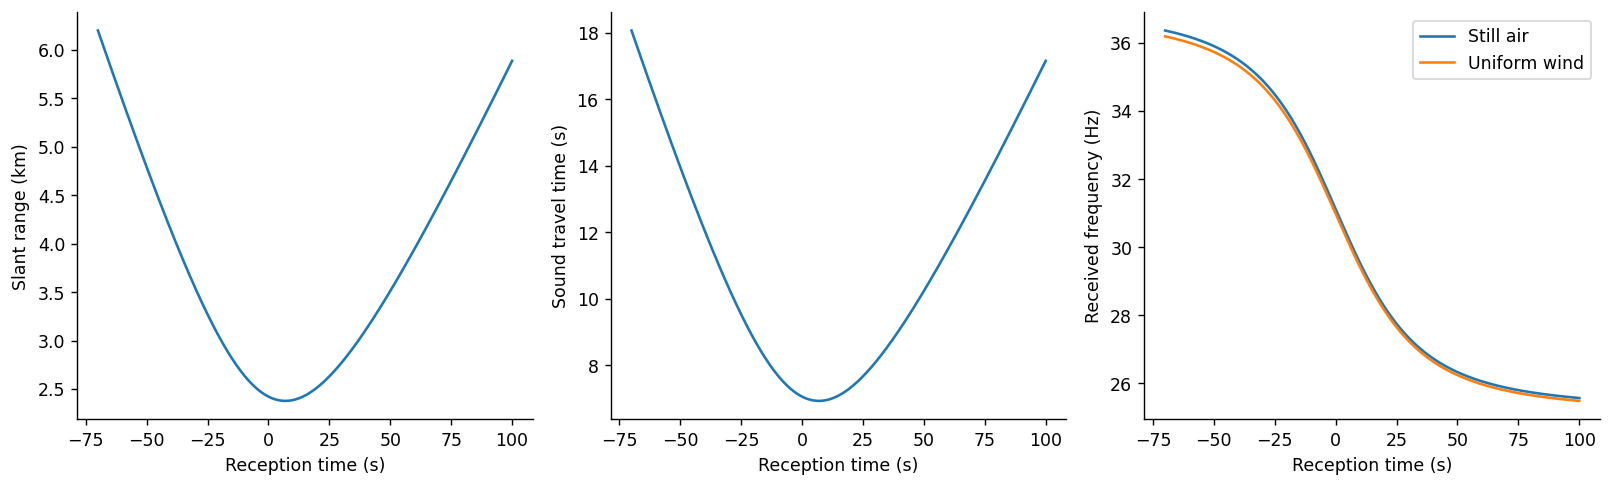

In [2]:
tr=np.linspace(-70,100,501)
factor,te,slant=received_doppler(trajectory,tr,observer)
wind_factor,wind_te,wind_slant=received_doppler(trajectory,tr,observer,wind_m_s=(7.,-4.,1.))
fig,axes=plt.subplots(1,3,figsize=(13,4))
axes[0].plot(tr,slant/1000);axes[0].set(xlabel='Reception time (s)',ylabel='Slant range (km)')
axes[1].plot(tr,tr-te);axes[1].set(xlabel='Reception time (s)',ylabel='Sound travel time (s)')
axes[2].plot(tr,30*factor,label='Still air');axes[2].plot(tr,30*wind_factor,label='Uniform wind')
axes[2].set(xlabel='Reception time (s)',ylabel='Received frequency (Hz)');axes[2].legend()
plt.tight_layout();plt.show()

## 2. Numerical checks

Finite-difference agreement, inverse-time recovery and Doppler sign validate implementation consistency only. They do not measure real-world error.

In [3]:
t=np.array([-35.,-10.,20.,50.]);wind=(7.,-4.,1.);eps=1e-3
lag,derivative,_=propagation(trajectory,t,observer,343.,wind)
numeric=1+(propagation(trajectory,t+eps,observer,343.,wind)[0]-propagation(trajectory,t-eps,observer,343.,wind)[0])/(2*eps)
error=np.max(np.abs(derivative-numeric))
_,recovered,_=received_doppler(trajectory,t+lag,observer,343.,wind)
assert error<1e-7
assert np.max(np.abs(recovered-t))<1e-7
print(f'Max derivative error: {error:.3g}; emission-time recovery passed')
p,v=trajectory(t);r=np.linalg.norm(p,axis=1);rdot=np.sum(p*v,axis=1)/r
assert np.allclose(propagation(trajectory,t,observer)[1],1+rdot/343.,atol=1e-12)
print('Still-air Doppler sign check passed')

Max derivative error: 2.02e-11; emission-time recovery passed
Still-air Doppler sign check passed


## 3. Mirror ambiguity and pitch drift

For a straight flight path in still air, observers mirrored across its vertical plane can have identical slant-range histories. A near-zero curve mismatch therefore does not guarantee a unique geographic solution. Unknown source pitch introduces another ambiguity.

Mirror observers have indistinguishable Doppler factors in this synthetic geometry.


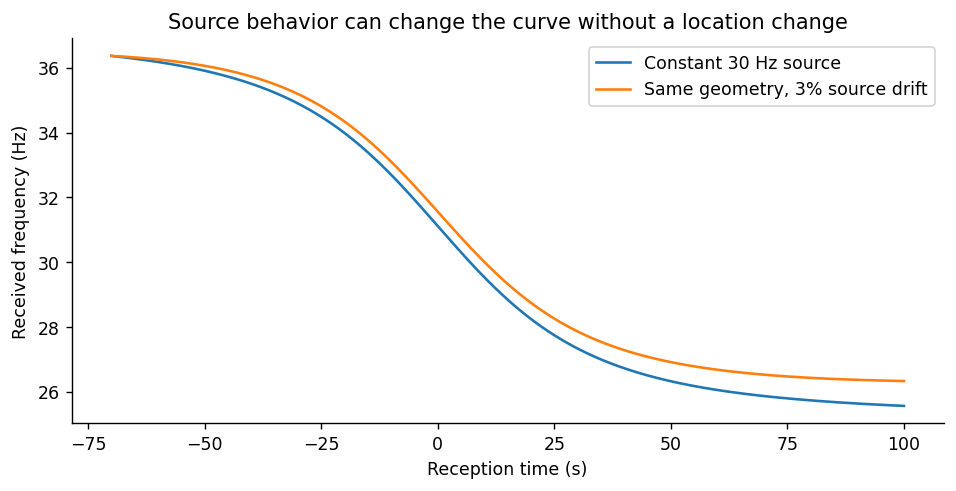

In [4]:
mirror=np.array([0.,4400.,0.])
mirrored,_,_=received_doppler(trajectory,tr,mirror)
assert np.allclose(factor,mirrored,atol=1e-12)
print('Mirror observers have indistinguishable Doppler factors in this synthetic geometry.')
source=30*(1+0.03*(te-te.min())/(te.max()-te.min()))
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(tr,30*factor,label='Constant 30 Hz source')
ax.plot(tr,source*factor,label='Same geometry, 3% source drift')
ax.set(xlabel='Reception time (s)',ylabel='Received frequency (Hz)',title='Source behavior can change the curve without a location change')
ax.legend();plt.show()

## Conclusion

Retarded time and three-dimensional geometry are necessary but not sufficient. Independent events, accurately constrained source behavior, propagation conditions and held-out validation are needed before making strong localization claims. This notebook deliberately stops short of a real-data geolocation claim.